# Mini DDPM pada MNIST
Model difusi Mini DDPM yang dibangun dari nol dengan PyTorch dan dilatih pada MNIST 28x28. Notebook ini berdiri sendiri dan menghasilkan digit tulisan tangan dari noise murni.

## 1. Import library (Ketua)
Semua import dikumpulkan di satu sel ini supaya gampang dicek. Yang dipakai cuma library, tidak ada import antar-file.

In [37]:
import copy
import json
import math
import random
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

## 2. Config (Ketua)
Semua angka dan path proyek disimpan di sini, jadi sel lain cukup membaca `config.X` tanpa menulis angka sendiri. Isinya dibagi tiga sel (root repo, nilai baseline, lalu sisanya) dan harus dijalankan berurutan dari atas. `BATCH_SIZE` dan `EPOCHS` bisa disesuaikan dengan kecepatan training.

In [38]:
# Root repo: folder kerja saat ini, atau folder induknya kalau dijalankan dari notebooks/
BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

In [39]:
config = SimpleNamespace(
    SEED=42,
    LEARNING_RATE=2e-4,
    # nilai baseline disesuaikan dengan kecepatan training.
    BATCH_SIZE=64,
    EPOCHS=20,
    NUM_WORKERS=0,
    T=1000,
    # Acuan untuk T=1000; Diffusion menskalakan beta dengan BETA_REFERENCE_T / T
    BETA_START=1e-4,
    BETA_END=0.02,
    BETA_REFERENCE_T=1000,
    IMAGE_SIZE=28,
    MODEL_PARAMS={
        "in_channels": 1,
        "base_channels": 64,
        "channel_mults": (1, 2, 2),
        "time_emb_dim": 128,
    },
)

In [40]:
config.SAMPLE_EVERY_N_EPOCHS = 5
config.NUM_SAMPLE_IMAGES = 16

config.SMOKE_TEST = False
config.SMOKE_SUBSET_SIZE = 512
config.SMOKE_EPOCHS = 2
config.SMOKE_SAMPLE_EVERY = 1     # interval grid smoke test (harus <= SMOKE_EPOCHS)

# Path: semuanya diturunkan dari BASE_DIR (sel sebelumnya)
config.BASE_DIR = BASE_DIR
config.DATA_DIR = BASE_DIR / "data"
config.CHECKPOINT_DIR = BASE_DIR / "checkpoints"
config.RESULTS_DIR = BASE_DIR / "results"
config.LOSS_CURVES_DIR = config.RESULTS_DIR / "loss_curves"
config.SAMPLES_DIR = config.RESULTS_DIR / "samples"

## 3. Utils (Ketua)
Dua fungsi kecil yang dipakai semua bagian: `set_seed` supaya hasil acak bisa diulang, dan `get_device` untuk memilih cuda, mps, atau cpu. Device hanya ditentukan di `get_device`, jadi tidak ada sel lain yang menulis "cuda" atau "cpu" langsung.

In [41]:
def set_seed(seed):
    """Seed random, numpy, torch. Tanpa mode deterministik penuh agar training tidak melambat."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # sekaligus menyemai CUDA dan MPS

In [42]:
def get_device():
    """Device pertama yang tersedia: cuda, mps, cpu. Tanpa print."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

## 4. Dataset (Teman A)
MNIST diunduh otomatis ke `data/`, lalu tiap gambar diubah ke rentang [-1, 1] supaya sama dengan skala noise Gaussian yang dipakai diffusion. Model kita unconditional (nggak dikasih tahu digit berapa), jadi labelnya dibuang di sini dan tiap batch cuma berisi gambar.

In [43]:
class ImagesOnly(Dataset):
    """Bungkus dataset (gambar, label) supaya hanya mengembalikan gambar."""

    def __init__(self, base):
        self.base = base

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, _label = self.base[idx]  # label dibuang di sini
        return image

`get_dataloader` membaca semua pengaturan dari argumen `cfg`, bukan dari `config` global. Jadi `train` milik Teman B bisa ngirim salinan config dengan `SMOKE_TEST` sendiri. Kalau mode smoke nyala, yang dipakai cuma `SMOKE_SUBSET_SIZE` gambar pertama biar ujinya cepat.

In [44]:
def get_dataloader(cfg):
    """DataLoader MNIST: tiap batch satu tensor float (B, 1, 28, 28) dalam [-1, 1], tanpa label."""
    to_range = transforms.Compose([
        transforms.ToTensor(),                 # piksel 0..255 -> float [0, 1], shape (1, 28, 28)
        transforms.Normalize((0.5,), (0.5,)),  # (x - 0.5) / 0.5 -> [-1, 1]
    ])
    mnist = datasets.MNIST(root=cfg.DATA_DIR, train=True, download=True, transform=to_range)
    data = ImagesOnly(mnist)
    if cfg.SMOKE_TEST:
        data = Subset(data, range(min(cfg.SMOKE_SUBSET_SIZE, len(data))))
    return DataLoader(
        data,
        batch_size=cfg.BATCH_SIZE,
        shuffle=True,
        num_workers=cfg.NUM_WORKERS,
        drop_last=False,
    )

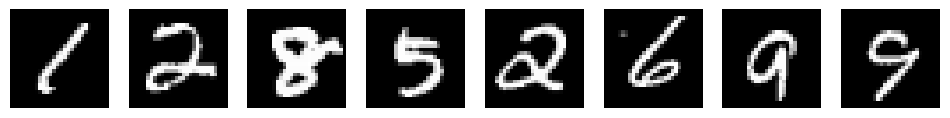

dataset OK


In [45]:
# Contoh gambar dari satu batch (dikembalikan ke [0, 1] hanya untuk ditampilkan)
cfg_full = SimpleNamespace(**copy.deepcopy(vars(config)))
cfg_full.SMOKE_TEST = False
batch = next(iter(get_dataloader(cfg_full)))
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, img in zip(axes, batch[:8]):
    ax.imshow(((img[0] + 1) / 2).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()
print("dataset OK")

## 5. Visualize (Teman A)
Dua fungsi buat nyimpen hasil: `save_image_grid` untuk grid gambar dan `plot_loss` untuk grafik loss. Keduanya nyimpen ke file sekaligus nampilin di notebook, dan dipakai `train` serta `sample` milik Teman B.

Gambar dari model ada di rentang [-1, 1], sedangkan file PNG butuh [0, 1], jadi dikonversi dulu dengan `(x + 1) / 2`. Tensor juga dipindah ke CPU dulu, karena hasil sampling bisa masih ada di GPU.

In [46]:
def save_image_grid(images, path):
    """Simpan tensor (N, 1, 28, 28) dalam [-1, 1] sebagai satu grid PNG, lalu tampilkan di notebook."""
    images = images.detach().cpu().float().clamp(-1.0, 1.0)
    images = (images + 1.0) / 2.0
    nrow = math.ceil(math.sqrt(images.shape[0]))  # grid sepersegi mungkin
    grid = make_grid(images, nrow=nrow, padding=2, pad_value=1.0)
    grid_np = grid.permute(1, 2, 0).numpy()

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.imsave(path, grid_np)

    fig, ax = plt.subplots(figsize=(max(2, nrow * 0.9), max(2, nrow * 0.9)))
    ax.imshow(grid_np)
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")
    plt.show()
    plt.close(fig)

`plot_loss` menerima dict `{label: [loss per epoch]}`, jadi bisa satu garis (satu konfigurasi) atau beberapa garis sekaligus buat bandingin eksperimen. Kalau dikasih list biasa, otomatis dianggap satu seri bernama "loss".

In [47]:
def plot_loss(series, path):
    """Grafik loss per epoch dari {label: [loss, ...]} (atau satu list), simpan ke file lalu tampilkan."""
    if not isinstance(series, dict):
        series = {"loss": list(series)}
    fig, ax = plt.subplots(figsize=(6, 4))
    for label, losses in series.items():
        epochs = range(1, len(losses) + 1)
        ax.plot(epochs, losses, marker="o", markersize=3, label=label)
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE loss")
    ax.set_title("Loss training per epoch")
    ax.grid(alpha=0.3)
    ax.legend()

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight", dpi=120)
    plt.show()
    plt.close(fig)

## 6. Model (Ketua)
Di bagian ini kita bikin otak DDPM-nya: timestep embedding, blok dasar, dan U-Net yang menebak noise di gambar.

In [48]:
def _group_norm(channels):
    # Jumlah grup terbesar dari (8, 4, 2, 1) yang habis membagi jumlah channel
    for groups in (8, 4, 2, 1):
        if channels % groups == 0:
            return nn.GroupNorm(groups, channels)

Angka `t` mentah susah dipakai jaringan, jadi diubah jadi vektor berisi gelombang sin dan cos dengan frekuensi berbeda-beda, mirip jarum jam, menit, dan detik yang bareng-bareng menunjuk satu waktu. Model perlu tahu `t` karena kerjanya beda: di `t` kecil cuma merapikan detail, di `t` besar harus menebak bentuk digit dari noise.

In [49]:
class SinusoidalTimeEmbedding(nn.Module):
    """t (B,) bertipe long -> vektor (B, dim) berisi sin dan cos berbagai frekuensi."""

    def __init__(self, dim):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError("time_emb_dim harus genap")
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        # Frekuensi turun geometris dari 1 ke 1/10000
        exponent = -math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half
        freqs = torch.exp(exponent)
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=1)

`ResBlock` itu dua konvolusi 3x3 yang di tengahnya ditambah embedding waktu, supaya tiap blok tahu lagi di `t` berapa. Inputnya juga dijumlahkan ke keluaran (jalan pintas residual) biar training lebih stabil.

In [50]:
class ResBlock(nn.Module):
    """Dua konvolusi 3x3; embedding waktu ditambahkan di antaranya."""

    def __init__(self, in_ch, out_ch, time_emb_dim):
        super().__init__()
        self.norm1 = _group_norm(in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Sequential(nn.SiLU(), nn.Linear(time_emb_dim, out_ch))
        self.norm2 = _group_norm(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.act = nn.SiLU()
        # Jalan pintas residual; 1x1 conv bila jumlah channel berubah
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(self.act(self.norm1(x)))
        h = h + self.time_proj(t_emb)[:, :, None, None]  # (B,C) -> (B,C,1,1), disiarkan ke semua piksel
        h = self.conv2(self.act(self.norm2(h)))
        return h + self.shortcut(x)

`Downsample` memperkecil gambar jadi setengahnya (28 → 14 → 7) pakai konvolusi stride 2. `Upsample` kebalikannya: ukuran gambar digandakan (7 → 14 → 28), lalu dihaluskan dengan satu konvolusi.

In [51]:
class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)

In [52]:
class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        return self.conv(self.up(x))

`UNet` punya jalur turun (28 → 14 → 7), satu bagian tengah di 7x7, lalu jalur naik (7 → 14 → 28). Hasil tiap level di jalur turun disimpan, lalu ditempel (skip connection) ke level naik yang ukurannya sama, supaya detail halus yang hilang waktu diperkecil tetap kebawa. Keluarannya prediksi noise berukuran sama dengan input, yaitu (B, 1, 28, 28).

In [53]:
class UNet(nn.Module):
    def __init__(self, in_channels, base_channels, channel_mults, time_emb_dim):
        super().__init__()
        n = len(channel_mults)
        if not 1 <= n <= 3:
            raise ValueError("channel_mults harus berisi 1 sampai 3 level (maks. dua downsampling)")
        chs = [base_channels * m for m in channel_mults]
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim),
        )
        self.init_conv = nn.Conv2d(in_channels, chs[0], 3, padding=1)
        self.down_blocks = nn.ModuleList(
            [ResBlock(chs[max(i - 1, 0)], chs[i], time_emb_dim) for i in range(n)]
        )
        self.downsamples = nn.ModuleList([Downsample(chs[i]) for i in range(n - 1)])
        self.mid1 = ResBlock(chs[-1], chs[-1], time_emb_dim)
        self.mid2 = ResBlock(chs[-1], chs[-1], time_emb_dim)

        # Jalur naik dari level terdalam: input = hasil level bawah + skip
        self.up_blocks = nn.ModuleList()
        for k in range(n):
            i = n - 1 - k
            self.up_blocks.append(
                ResBlock(chs[i] + chs[min(i + 1, n - 1)], chs[i], time_emb_dim)
            )
        self.upsamples = nn.ModuleList([Upsample(chs[n - 1 - k]) for k in range(n - 1)])
        self.out_norm = _group_norm(chs[0])
        self.out_conv = nn.Conv2d(chs[0], in_channels, 3, padding=1)
        self.act = nn.SiLU()

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        h = self.init_conv(x)
        skips = []
        for i, block in enumerate(self.down_blocks):
            h = block(h, t_emb)
            skips.append(h)
            if i < len(self.downsamples):
                h = self.downsamples[i](h)
        h = self.mid2(self.mid1(h, t_emb), t_emb)

        for k, block in enumerate(self.up_blocks):
            h = torch.cat([h, skips.pop()], dim=1)
            h = block(h, t_emb)
            if k < len(self.upsamples):
                h = self.upsamples[k](h)
        return self.out_conv(self.act(self.out_norm(h)))

## 7. Diffusion (Ketua)
Gambar dirusak pelan-pelan jadi noise lewat T langkah kecil: `beta` adalah porsi noise tiap langkah, dan `alpha_bar` adalah sisa gambar asli setelah t langkah (turun dari sekitar 1 ke sekitar 0). Karena itu gambar di langkah t bisa dihitung langsung dari gambar bersih dengan satu rumus. Kalau T diubah, beta dikalikan `BETA_REFERENCE_T / T` supaya langkah terakhir tetap noise murni, lalu sampling membalik prosesnya dari noise murni, langkah T-1 sampai 0.

In [54]:
def _extract(values, t, x):
    """Ambil values[t] lalu ubah ke (B,1,1,1) agar bisa dikalikan dengan x (B,C,H,W)."""
    out = values.to(x.device)[t.to(x.device)]
    return out.reshape(t.shape[0], *([1] * (x.dim() - 1)))

In [55]:
class Diffusion:
    def __init__(self, T, device=None,
                 beta_start=config.BETA_START, beta_end=config.BETA_END):
        # Beta diskalakan BETA_REFERENCE_T / T supaya total noise tetap sama saat T berubah
        scale = config.BETA_REFERENCE_T / T
        if beta_end * scale >= 1.0:
            raise ValueError(f"T={T} terlalu kecil: beta akhir jadi >= 1")
        self.T = T
        self.betas = torch.linspace(beta_start * scale, beta_end * scale, T, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)
        self.sqrt_alpha_bars = self.alpha_bars.sqrt()
        self.sqrt_one_minus_alpha_bars = (1.0 - self.alpha_bars).sqrt()
        self.sqrt_recip_alphas = (1.0 / self.alphas).sqrt()
        self.sqrt_betas = self.betas.sqrt()

    def add_noise(self, x0, t, noise):
        return (_extract(self.sqrt_alpha_bars, t, x0) * x0
                + _extract(self.sqrt_one_minus_alpha_bars, t, x0) * noise)

    def sample_timesteps(self, batch_size, device):
        return torch.randint(0, self.T, (batch_size,), device=device)

    @torch.no_grad()
    def sample(self, model, num_images, device):
        # Reverse process; mode eval/train model diatur pemanggil (train)
        size = config.IMAGE_SIZE
        shape = (num_images, config.MODEL_PARAMS["in_channels"], size, size)
        x = torch.randn(shape, device=device)
        for i in reversed(range(self.T)):
            t = torch.full((num_images,), i, device=device, dtype=torch.long)
            pred_noise = model(x, t)
            coef = _extract(self.betas, t, x) / _extract(self.sqrt_one_minus_alpha_bars, t, x)
            mean = _extract(self.sqrt_recip_alphas, t, x) * (x - coef * pred_noise)
            if i > 0:
                x = mean + _extract(self.sqrt_betas, t, x) * torch.randn_like(x)
            else:
                x = mean
        return x.clamp(-1.0, 1.0)

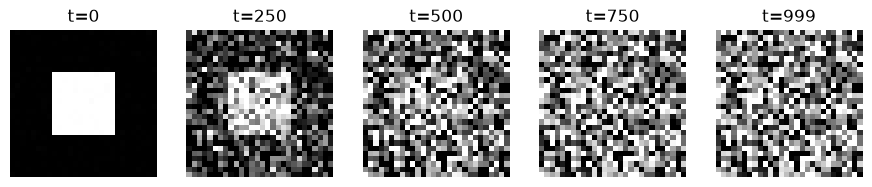

In [56]:
# Visualisasi forward process: makin besar t, makin berisik
set_seed(config.SEED)
device = get_device()
d = Diffusion(config.T, device)
x0 = torch.full((8, config.MODEL_PARAMS["in_channels"], config.IMAGE_SIZE, config.IMAGE_SIZE), -1.0, device=device)
x0[:, :, 8:20, 8:20] = 1.0
noise = torch.randn_like(x0)
ts = [0, d.T // 4, d.T // 2, 3 * d.T // 4, d.T - 1]
fig, axes = plt.subplots(1, len(ts), figsize=(2.2 * len(ts), 2.6))
for ax, t_val in zip(axes, ts):
    t = torch.full((1,), t_val, device=device, dtype=torch.long)
    xt = d.add_noise(x0[:1], t, noise[:1])
    ax.imshow(xt[0, 0].cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"t={t_val}")
    ax.axis("off")
plt.show()

## 8. Experiments (Teman B)
Tiap eksperimen cuma boleh ngubah satu hal, learning rate atau T, sisanya ikut baseline di `config`. Jadi kalau hasilnya beda, kita tahu penyebabnya dari variabel yang mana.

In [57]:
EXPERIMENTS = {
    "baseline": {},                      # semua nilai dari config
    "lr_1e-4": {"LEARNING_RATE": 1e-4},
    "lr_5e-4": {"LEARNING_RATE": 5e-4},
    "T_250": {"T": 250},
    "T_500": {"T": 500},
}

`_resolve_run` menggabungkan baseline dengan timpaan eksperimen ke dalam **salinan** config, jadi `config` aslinya nggak pernah diubah. Di sini juga semua nama file ditentukan, dan akhiran `_smoke` ditambahkan kalau mode smoke supaya hasil uji nggak menimpa hasil asli.

In [58]:
def _resolve_run(name, smoke=None):
    """Nilai efektif satu konfigurasi sebagai salinan lokal. smoke=None ikut config.SMOKE_TEST."""
    if name not in EXPERIMENTS:
        raise KeyError(f"Konfigurasi '{name}' tidak ada. Pilihan: {list(EXPERIMENTS)}")
    extra = set(EXPERIMENTS[name]) - {"LEARNING_RATE", "T"}
    if extra:
        raise ValueError(f"{name}: hanya LEARNING_RATE dan T yang boleh ditimpa, bukan {extra}")
    cfg = SimpleNamespace(**copy.deepcopy(vars(config)))  # salinan; config asli tidak disentuh
    for key, value in EXPERIMENTS[name].items():
        setattr(cfg, key, value)
    cfg.SMOKE_TEST = config.SMOKE_TEST if smoke is None else smoke
    suffix = "_smoke" if cfg.SMOKE_TEST else ""
    tag = name + suffix
    return SimpleNamespace(
        name=name, cfg=cfg, tag=tag, suffix=suffix,
        lr=cfg.LEARNING_RATE, T=cfg.T,
        epochs=cfg.SMOKE_EPOCHS if cfg.SMOKE_TEST else cfg.EPOCHS,
        sample_every=cfg.SMOKE_SAMPLE_EVERY if cfg.SMOKE_TEST else cfg.SAMPLE_EVERY_N_EPOCHS,
        checkpoint_path=cfg.CHECKPOINT_DIR / f"ddpm_{tag}.pt",
        loss_json=cfg.LOSS_CURVES_DIR / f"{tag}_loss.json",
        loss_png=cfg.LOSS_CURVES_DIR / f"{tag}_loss.png",
    )

## 9. Train (Teman B)
Tiap iterasi: ambil batch gambar, pilih `t` acak, tambahkan noise, suruh model menebak noise itu, lalu hitung MSE antara noise asli dan tebakan. Parameter `smoke` di `train` cuma jalan kalau `get_dataloader` membaca `SMOKE_TEST` dan `SMOKE_SUBSET_SIZE` dari argumen `cfg`, bukan dari `config` global.

In [59]:
def _train_one_epoch(model, loader, diffusion, optimizer, device):
    """Satu putaran data; mengembalikan rata-rata loss MSE per batch."""
    model.train()
    total = torch.zeros((), device=device)
    n_batches = 0
    for x0 in loader:  # tiap batch: satu tensor (B, 1, 28, 28) dalam [-1, 1]
        x0 = x0.to(device)
        t = diffusion.sample_timesteps(x0.shape[0], device)
        noise = torch.randn_like(x0)
        x_t = diffusion.add_noise(x0, t, noise)
        loss = nn.functional.mse_loss(model(x_t, t), noise)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        total += loss.detach()  # tetap di device, tanpa sinkronisasi tiap batch
        n_batches += 1
    return (total / n_batches).item()

Checkpoint cuma berisi tensor, angka, dan dict biasa, jadi aman dibuka dengan `torch.load(weights_only=True)`. Isinya cukup buat `sample` membangun ulang model, termasuk T, karena T yang salah bikin noise schedule-nya beda.

In [60]:
def _save_checkpoint(path, model, optimizer, T, model_params, epoch):
    """Simpan lima isi checkpoint; tanpa objek config atau Path."""
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state_dict": model.state_dict(),
        "T": int(T),
        "MODEL_PARAMS": dict(model_params),
        "epoch": int(epoch),
        "optimizer_state_dict": optimizer.state_dict(),
    }, path)

In [61]:
def _save_loss_record(run, losses, epoch_seconds):
    """Catatan loss per epoch ke JSON, supaya bagian 13 bisa membandingkan tanpa melatih ulang."""
    run.loss_json.parent.mkdir(parents=True, exist_ok=True)
    record = {
        "name": run.name,
        "smoke": run.cfg.SMOKE_TEST,
        "learning_rate": run.lr,
        "T": run.T,
        "losses": losses,
        "epoch_seconds": epoch_seconds,  # waktu training per epoch, tanpa sampling
    }
    run.loss_json.write_text(json.dumps(record, indent=2))

In [62]:
def _save_training_grid(model, diffusion, run, epoch, device):
    """Grid sampel di tengah training; mengembalikan lama sampling dalam detik."""
    model.eval()
    start = time.perf_counter()
    images = diffusion.sample(model, run.cfg.NUM_SAMPLE_IMAGES, device)  # sudah tanpa gradien
    seconds = time.perf_counter() - start
    model.train()
    save_image_grid(images, run.cfg.SAMPLES_DIR / f"{run.tag}_epoch{epoch:03d}.png")
    return seconds

In [63]:
def _log_epoch(run, epoch, loss, train_s, sample_s, elapsed_s):
    """Cetak progres satu epoch plus perkiraan sisa waktu dari rata-rata epoch sejauh ini."""
    eta_min = elapsed_s / epoch * (run.epochs - epoch) / 60
    msg = f"[{run.tag}] epoch {epoch}/{run.epochs}  loss={loss:.4f}  train={train_s:.1f}s"
    if sample_s:
        msg += f"  sampling={sample_s:.1f}s"
    print(f"{msg}  sisa≈{eta_min:.1f} menit")

In [64]:
def train(name="baseline", smoke=None):
    """Latih satu konfigurasi EXPERIMENTS. smoke=None ikut config.SMOKE_TEST; True/False menimpanya"""
    run = _resolve_run(name, smoke)
    set_seed(config.SEED)  # inisialisasi dan urutan data sama untuk semua eksperimen
    device = get_device()
    loader = get_dataloader(run.cfg)
    model = UNet(**run.cfg.MODEL_PARAMS).to(device)
    diffusion = Diffusion(run.T, device)
    optimizer = torch.optim.Adam(model.parameters(), lr=run.lr)
    print(f"[{run.tag}] device={device}  lr={run.lr:g}  T={run.T}  epochs={run.epochs}")

    losses, epoch_seconds, start_all = [], [], time.perf_counter()
    for epoch in range(1, run.epochs + 1):
        start = time.perf_counter()
        losses.append(_train_one_epoch(model, loader, diffusion, optimizer, device))
        epoch_seconds.append(time.perf_counter() - start)
        is_grid_epoch = epoch % run.sample_every == 0
        if is_grid_epoch or epoch == run.epochs:  # checkpoint berkala + akhir, satu file ditimpa
            _save_checkpoint(run.checkpoint_path, model, optimizer, run.T, run.cfg.MODEL_PARAMS, epoch)
        sample_s = _save_training_grid(model, diffusion, run, epoch, device) if is_grid_epoch else 0.0
        _save_loss_record(run, losses, epoch_seconds)
        _log_epoch(run, epoch, losses[-1], epoch_seconds[-1], sample_s, time.perf_counter() - start_all)

    plot_loss({run.name: losses}, run.loss_png)
    return run.checkpoint_path, losses

## 10. Sample (Teman B)
`sample(path_checkpoint)` membuka checkpoint, membangun ulang `UNet` dan `Diffusion` dari isinya (bukan dari `config`), lalu memanggil `Diffusion.sample` milik ketua. Jadi fungsi ini nggak punya logika reverse process sendiri.

In [65]:
def sample(path_checkpoint):
    """Muat checkpoint, bangun ulang model dan noise schedule dari isinya, lalu buat grid sampel."""
    path_checkpoint = Path(path_checkpoint)
    device = get_device()
    ckpt = torch.load(path_checkpoint, map_location=device, weights_only=True)
    model = UNet(**ckpt["MODEL_PARAMS"]).to(device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    diffusion = Diffusion(ckpt["T"], device)  # T dari checkpoint, bukan config
    set_seed(config.SEED)  # noise awal sama tiap dipanggil, biar grid antar-eksperimen adil
    images = diffusion.sample(model, config.NUM_SAMPLE_IMAGES, device)
    save_image_grid(images, config.SAMPLES_DIR / f"{path_checkpoint.stem}_final.png")
    print(f"sample: {path_checkpoint.name}  T={ckpt['T']}  epoch={ckpt['epoch']}  ->  {images.shape[0]} gambar")
    return images

## 12. Eksekusi baseline (Teman B)
Latih konfigurasi `baseline`: grafik loss dan grid tiap N epoch langsung tampil dan tersimpan di `results/`. Setelah itu kita sampling ulang dari checkpoint untuk memastikan model bisa dipakai tanpa melatih lagi.

[baseline] device=cuda  lr=0.0002  T=1000  epochs=20
[baseline] epoch 1/20  loss=0.0503  train=78.9s  sisa≈25.0 menit
[baseline] epoch 2/20  loss=0.0284  train=84.1s  sisa≈24.4 menit
[baseline] epoch 3/20  loss=0.0264  train=86.1s  sisa≈23.5 menit
[baseline] epoch 4/20  loss=0.0253  train=86.1s  sisa≈22.3 menit


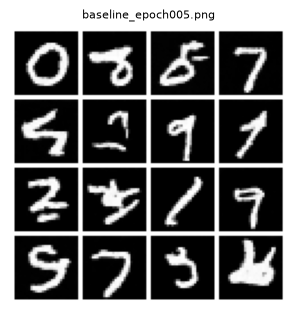

[baseline] epoch 5/20  loss=0.0248  train=86.2s  sampling=9.6s  sisa≈21.6 menit
[baseline] epoch 6/20  loss=0.0242  train=87.0s  sisa≈20.2 menit
[baseline] epoch 7/20  loss=0.0238  train=86.2s  sisa≈18.7 menit
[baseline] epoch 8/20  loss=0.0236  train=86.2s  sisa≈17.3 menit
[baseline] epoch 9/20  loss=0.0232  train=86.2s  sisa≈15.8 menit


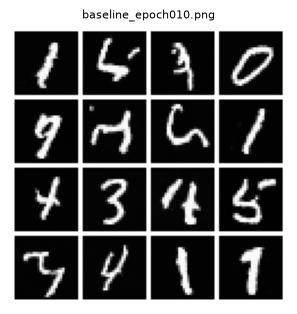

[baseline] epoch 10/20  loss=0.0233  train=86.1s  sampling=11.8s  sisa≈14.6 menit
[baseline] epoch 11/20  loss=0.0231  train=86.4s  sisa≈13.1 menit
[baseline] epoch 12/20  loss=0.0231  train=86.7s  sisa≈11.6 menit
[baseline] epoch 13/20  loss=0.0226  train=86.5s  sisa≈10.2 menit
[baseline] epoch 14/20  loss=0.0226  train=86.3s  sisa≈8.7 menit


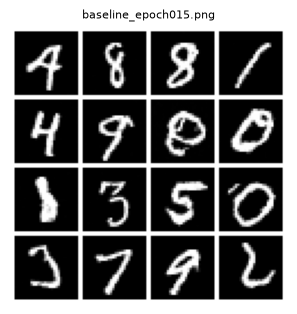

[baseline] epoch 15/20  loss=0.0224  train=86.2s  sampling=9.7s  sisa≈7.3 menit
[baseline] epoch 16/20  loss=0.0221  train=86.2s  sisa≈5.8 menit
[baseline] epoch 17/20  loss=0.0223  train=86.2s  sisa≈4.4 menit
[baseline] epoch 18/20  loss=0.0223  train=86.2s  sisa≈2.9 menit
[baseline] epoch 19/20  loss=0.0223  train=86.2s  sisa≈1.5 menit


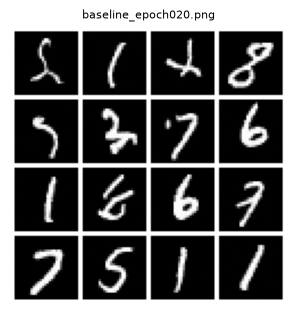

[baseline] epoch 20/20  loss=0.0222  train=86.2s  sampling=9.9s  sisa≈0.0 menit


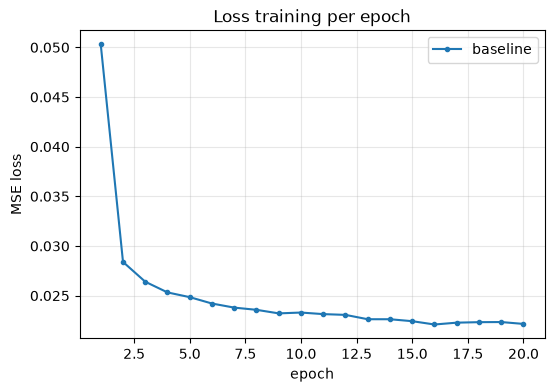

In [66]:
path_baseline, losses_baseline = train("baseline")

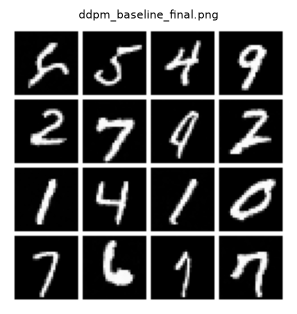

sample: ddpm_baseline.pt  T=1000  epoch=20  ->  16 gambar


In [67]:
images_baseline = sample(path_baseline)

## 13. Eksperimen dan hasil (Teman B)
Sisa konfigurasi dilatih satu per satu, lalu loss-nya dibandingkan dalam dua grafik: kelompok learning rate dan kelompok T. Ingat, loss rendah belum tentu digitnya bagus, jadi grid akhir tiap eksperimen juga perlu dilihat.

[lr_1e-4] device=cuda  lr=0.0001  T=1000  epochs=20
[lr_1e-4] epoch 1/20  loss=0.0583  train=86.2s  sisa≈27.3 menit
[lr_1e-4] epoch 2/20  loss=0.0309  train=86.1s  sisa≈25.8 menit
[lr_1e-4] epoch 3/20  loss=0.0279  train=86.2s  sisa≈24.4 menit
[lr_1e-4] epoch 4/20  loss=0.0263  train=86.2s  sisa≈23.0 menit


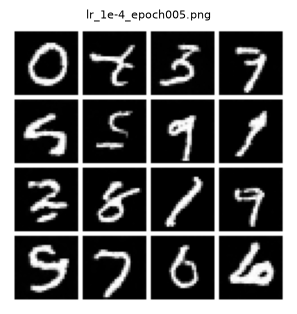

[lr_1e-4] epoch 5/20  loss=0.0257  train=86.2s  sampling=9.7s  sisa≈22.0 menit
[lr_1e-4] epoch 6/20  loss=0.0249  train=86.2s  sisa≈20.5 menit
[lr_1e-4] epoch 7/20  loss=0.0244  train=86.2s  sisa≈19.0 menit
[lr_1e-4] epoch 8/20  loss=0.0241  train=86.2s  sisa≈17.5 menit
[lr_1e-4] epoch 9/20  loss=0.0237  train=86.2s  sisa≈16.0 menit


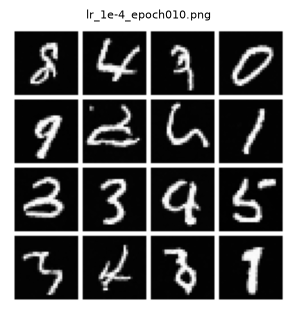

[lr_1e-4] epoch 10/20  loss=0.0237  train=86.3s  sampling=9.7s  sisa≈14.7 menit
[lr_1e-4] epoch 11/20  loss=0.0235  train=86.1s  sisa≈13.2 menit
[lr_1e-4] epoch 12/20  loss=0.0234  train=86.2s  sisa≈11.7 menit
[lr_1e-4] epoch 13/20  loss=0.0230  train=86.1s  sisa≈10.2 menit
[lr_1e-4] epoch 14/20  loss=0.0229  train=86.2s  sisa≈8.8 menit


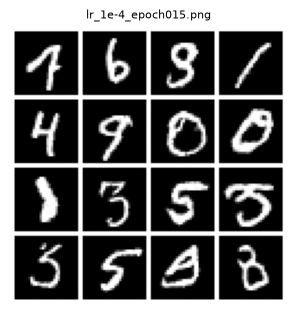

[lr_1e-4] epoch 15/20  loss=0.0227  train=88.1s  sampling=15.7s  sisa≈7.4 menit
[lr_1e-4] epoch 16/20  loss=0.0223  train=88.9s  sisa≈5.9 menit
[lr_1e-4] epoch 17/20  loss=0.0225  train=87.3s  sisa≈4.4 menit
[lr_1e-4] epoch 18/20  loss=0.0226  train=87.8s  sisa≈3.0 menit
[lr_1e-4] epoch 19/20  loss=0.0226  train=88.1s  sisa≈1.5 menit


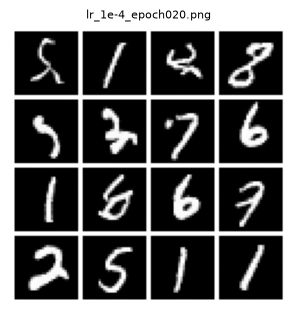

[lr_1e-4] epoch 20/20  loss=0.0224  train=86.9s  sampling=10.1s  sisa≈0.0 menit


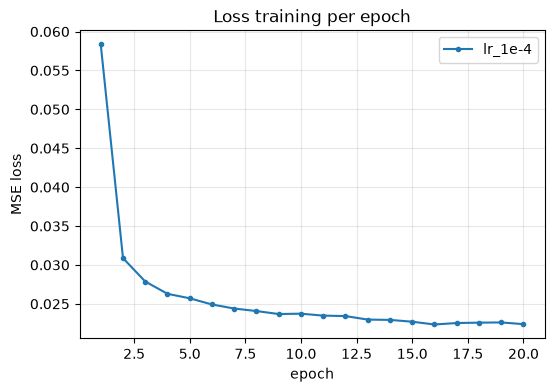

[lr_5e-4] device=cuda  lr=0.0005  T=1000  epochs=20
[lr_5e-4] epoch 1/20  loss=0.0467  train=87.0s  sisa≈27.5 menit
[lr_5e-4] epoch 2/20  loss=0.0274  train=86.9s  sisa≈26.1 menit
[lr_5e-4] epoch 3/20  loss=0.0258  train=87.5s  sisa≈24.7 menit
[lr_5e-4] epoch 4/20  loss=0.0248  train=87.2s  sisa≈23.2 menit


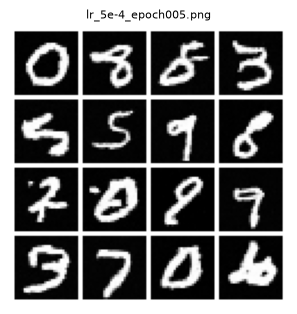

[lr_5e-4] epoch 5/20  loss=0.0245  train=87.6s  sampling=9.7s  sisa≈22.3 menit
[lr_5e-4] epoch 6/20  loss=0.0239  train=86.8s  sisa≈20.7 menit
[lr_5e-4] epoch 7/20  loss=0.0236  train=86.7s  sisa≈19.2 menit
[lr_5e-4] epoch 8/20  loss=0.0234  train=86.7s  sisa≈17.7 menit
[lr_5e-4] epoch 9/20  loss=0.0231  train=86.9s  sisa≈16.2 menit


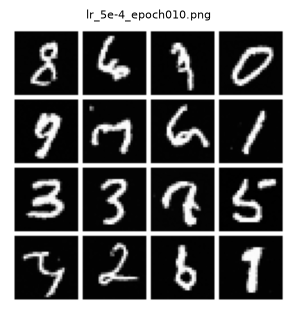

[lr_5e-4] epoch 10/20  loss=0.0232  train=87.0s  sampling=9.9s  sisa≈14.8 menit
[lr_5e-4] epoch 11/20  loss=0.0231  train=86.2s  sisa≈13.3 menit
[lr_5e-4] epoch 12/20  loss=0.0230  train=86.8s  sisa≈11.8 menit
[lr_5e-4] epoch 13/20  loss=0.0226  train=86.2s  sisa≈10.3 menit
[lr_5e-4] epoch 14/20  loss=0.0226  train=86.5s  sisa≈8.8 menit


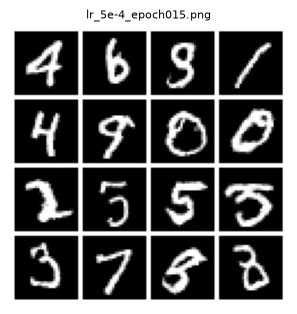

[lr_5e-4] epoch 15/20  loss=0.0224  train=86.8s  sampling=9.8s  sisa≈7.4 menit
[lr_5e-4] epoch 16/20  loss=0.0221  train=88.0s  sisa≈5.9 menit
[lr_5e-4] epoch 17/20  loss=0.0222  train=86.4s  sisa≈4.4 menit
[lr_5e-4] epoch 18/20  loss=0.0223  train=87.2s  sisa≈3.0 menit
[lr_5e-4] epoch 19/20  loss=0.0223  train=86.7s  sisa≈1.5 menit


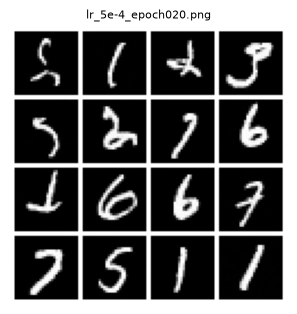

[lr_5e-4] epoch 20/20  loss=0.0221  train=86.8s  sampling=11.1s  sisa≈0.0 menit


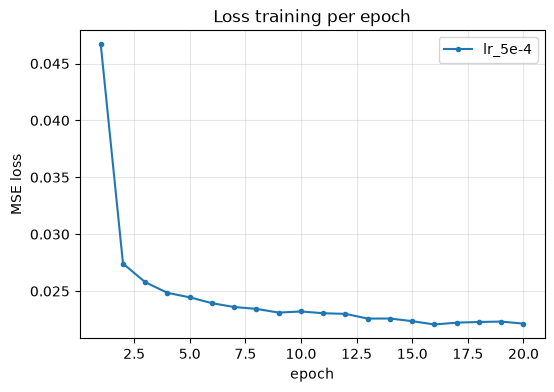

[T_250] device=cuda  lr=0.0002  T=250  epochs=20
[T_250] epoch 1/20  loss=0.0500  train=88.2s  sisa≈27.9 menit
[T_250] epoch 2/20  loss=0.0281  train=86.2s  sisa≈26.2 menit
[T_250] epoch 3/20  loss=0.0261  train=86.2s  sisa≈24.6 menit
[T_250] epoch 4/20  loss=0.0249  train=86.2s  sisa≈23.1 menit


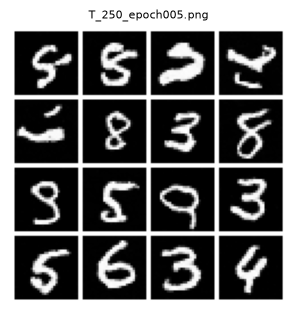

[T_250] epoch 5/20  loss=0.0245  train=86.2s  sampling=2.6s  sisa≈21.8 menit
[T_250] epoch 6/20  loss=0.0238  train=86.2s  sisa≈20.3 menit
[T_250] epoch 7/20  loss=0.0236  train=86.2s  sisa≈18.8 menit
[T_250] epoch 8/20  loss=0.0232  train=86.2s  sisa≈17.4 menit
[T_250] epoch 9/20  loss=0.0230  train=86.2s  sisa≈15.9 menit


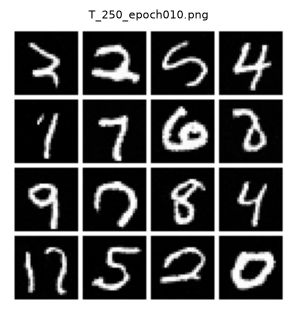

[T_250] epoch 10/20  loss=0.0229  train=86.2s  sampling=2.5s  sisa≈14.5 menit
[T_250] epoch 11/20  loss=0.0227  train=86.2s  sisa≈13.0 menit
[T_250] epoch 12/20  loss=0.0227  train=86.2s  sisa≈11.6 menit
[T_250] epoch 13/20  loss=0.0225  train=86.2s  sisa≈10.1 menit
[T_250] epoch 14/20  loss=0.0222  train=86.1s  sisa≈8.7 menit


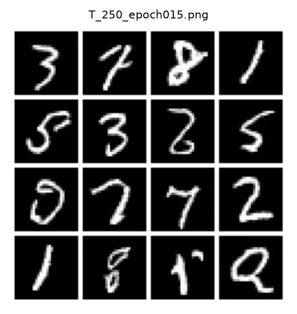

[T_250] epoch 15/20  loss=0.0221  train=86.2s  sampling=2.7s  sisa≈7.2 menit
[T_250] epoch 16/20  loss=0.0221  train=86.2s  sisa≈5.8 menit
[T_250] epoch 17/20  loss=0.0221  train=86.2s  sisa≈4.3 menit
[T_250] epoch 18/20  loss=0.0220  train=86.2s  sisa≈2.9 menit
[T_250] epoch 19/20  loss=0.0219  train=86.2s  sisa≈1.4 menit


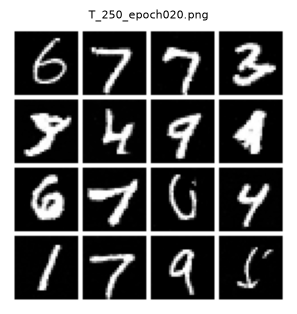

[T_250] epoch 20/20  loss=0.0218  train=86.2s  sampling=2.6s  sisa≈0.0 menit


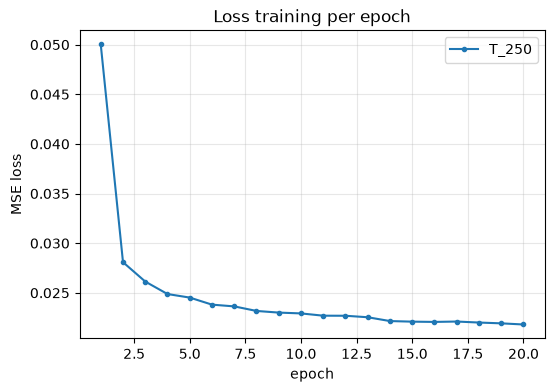

[T_500] device=cuda  lr=0.0002  T=500  epochs=20
[T_500] epoch 1/20  loss=0.0499  train=86.2s  sisa≈27.3 menit
[T_500] epoch 2/20  loss=0.0282  train=86.2s  sisa≈25.9 menit
[T_500] epoch 3/20  loss=0.0263  train=86.2s  sisa≈24.4 menit
[T_500] epoch 4/20  loss=0.0252  train=86.2s  sisa≈23.0 menit


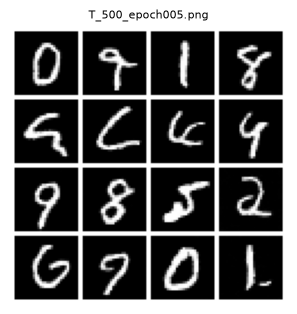

[T_500] epoch 5/20  loss=0.0247  train=86.7s  sampling=6.7s  sisa≈21.9 menit
[T_500] epoch 6/20  loss=0.0242  train=86.8s  sisa≈20.4 menit
[T_500] epoch 7/20  loss=0.0238  train=86.6s  sisa≈18.9 menit
[T_500] epoch 8/20  loss=0.0236  train=86.7s  sisa≈17.5 menit
[T_500] epoch 9/20  loss=0.0231  train=86.7s  sisa≈16.0 menit


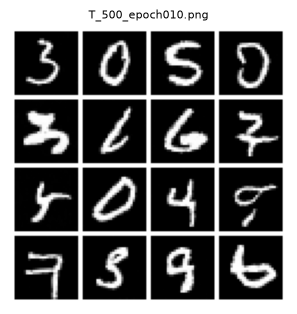

[T_500] epoch 10/20  loss=0.0233  train=86.6s  sampling=5.1s  sisa≈14.6 menit
[T_500] epoch 11/20  loss=0.0229  train=86.6s  sisa≈13.1 menit
[T_500] epoch 12/20  loss=0.0227  train=86.6s  sisa≈11.7 menit
[T_500] epoch 13/20  loss=0.0227  train=86.6s  sisa≈10.2 menit
[T_500] epoch 14/20  loss=0.0226  train=86.7s  sisa≈8.7 menit


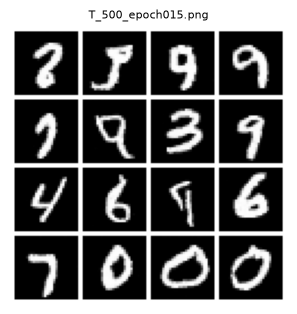

[T_500] epoch 15/20  loss=0.0222  train=86.6s  sampling=5.2s  sisa≈7.3 menit
[T_500] epoch 16/20  loss=0.0223  train=86.6s  sisa≈5.8 menit
[T_500] epoch 17/20  loss=0.0219  train=86.5s  sisa≈4.4 menit
[T_500] epoch 18/20  loss=0.0222  train=86.7s  sisa≈2.9 menit
[T_500] epoch 19/20  loss=0.0222  train=86.6s  sisa≈1.5 menit


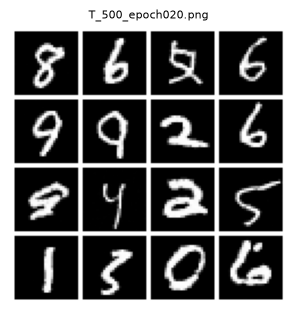

[T_500] epoch 20/20  loss=0.0219  train=86.5s  sampling=4.9s  sisa≈0.0 menit


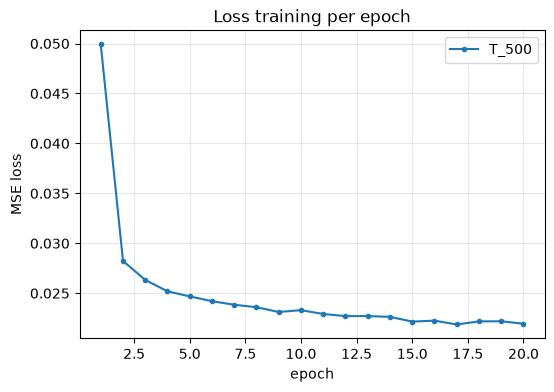

In [68]:
snapshot_13 = copy.deepcopy(vars(config))
# Baseline sudah dilatih di bagian 12; sisanya dilatih di sini
experiment_checkpoints = {"baseline": path_baseline}
for name in EXPERIMENTS:
    if name != "baseline":
        experiment_checkpoints[name], _ = train(name)

In [69]:
def _load_loss_records(names):
    """Baca catatan loss JSON tiap konfigurasi; mode smoke ikut config.SMOKE_TEST."""
    return {name: json.loads(_resolve_run(name).loss_json.read_text()) for name in names}

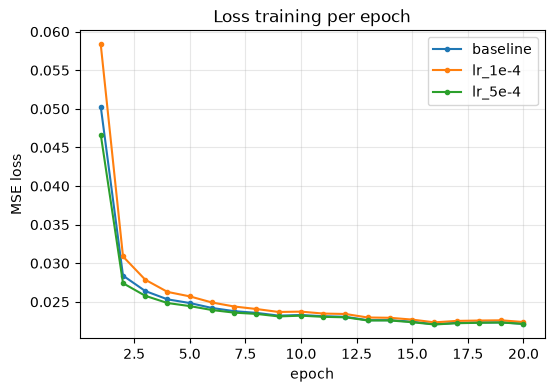

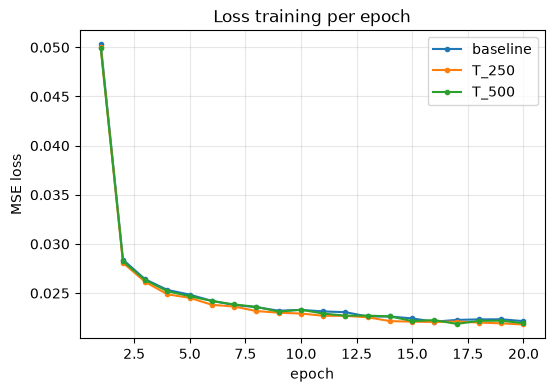

In [70]:
# Grafik perbandingan: tiap kelompok berisi baseline + eksperimen yang mengubah variabel itu
records = _load_loss_records(EXPERIMENTS)
suffix = _resolve_run("baseline").suffix
for variable in ("LEARNING_RATE", "T"):
    group = ["baseline"] + [n for n, o in EXPERIMENTS.items() if variable in o]
    series = {n: records[n]["losses"] for n in group}
    plot_loss(series, config.LOSS_CURVES_DIR / f"perbandingan_{variable.lower()}{suffix}.png")

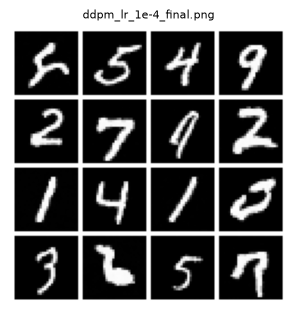

sample: ddpm_lr_1e-4.pt  T=1000  epoch=20  ->  16 gambar


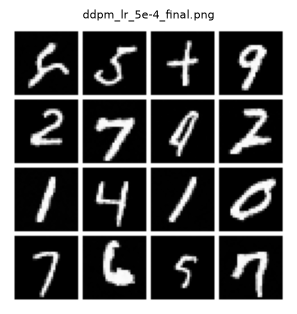

sample: ddpm_lr_5e-4.pt  T=1000  epoch=20  ->  16 gambar


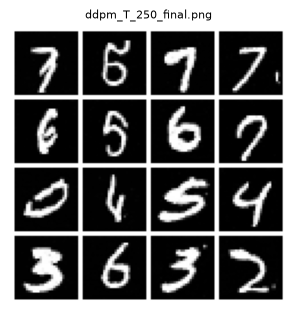

sample: ddpm_T_250.pt  T=250  epoch=20  ->  16 gambar


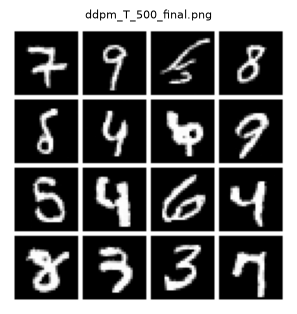

sample: ddpm_T_500.pt  T=500  epoch=20  ->  16 gambar


In [71]:
# Grid akhir tiap eksperimen dari checkpoint-nya (baseline sudah di bagian 12)
for name, path in experiment_checkpoints.items():
    if name != "baseline":
        sample(path)

In [72]:
# Tabel hasil ke results/experiments.md (smoke: experiments_smoke.md)
rows = ["| Konfigurasi | Learning rate | T | Epoch | Loss akhir | Loss minimum | Rata-rata detik/epoch | Catatan visual |",
        "|---|---|---|---|---|---|---|---|"]
for name, rec in records.items():
    secs, losses = rec["epoch_seconds"], rec["losses"]
    rows.append(f"| {name} | {rec['learning_rate']:g} | {rec['T']} | {len(losses)} | {losses[-1]:.4f} | "
                f"{min(losses):.4f} | {sum(secs) / len(secs):.1f} |  |")
header = ["# Hasil eksperimen", "",
          "Loss = rata-rata MSE noise per epoch. Kolom catatan visual diisi manual dari grid akhir.", ""]
md_path = config.RESULTS_DIR / f"experiments{suffix}.md"
md_path.parent.mkdir(parents=True, exist_ok=True)
md_path.write_text("\n".join(header + rows) + "\n")
print("\n".join(rows))

| Konfigurasi | Learning rate | T | Epoch | Loss akhir | Loss minimum | Rata-rata detik/epoch | Catatan visual |
|---|---|---|---|---|---|---|---|
| baseline | 0.0002 | 1000 | 20 | 0.0222 | 0.0221 | 85.8 |  |
| lr_1e-4 | 0.0001 | 1000 | 20 | 0.0224 | 0.0223 | 86.7 |  |
| lr_5e-4 | 0.0005 | 1000 | 20 | 0.0221 | 0.0221 | 86.9 |  |
| T_250 | 0.0002 | 250 | 20 | 0.0218 | 0.0218 | 86.3 |  |
| T_500 | 0.0002 | 500 | 20 | 0.0219 | 0.0219 | 86.5 |  |


## 14. Ringkasan hasil
Lima konfigurasi dilatih selama 20 epoch dengan batch size 64: baseline (learning rate 2e-4, T 1000), dua variasi learning rate (1e-4 dan 5e-4), dan dua variasi T (250 dan 500). Semuanya bisa membuat digit tulisan tangan dari noise murni, dan sebagian besar digitnya mudah dikenali.

Loss akhir hampir sama, yaitu 0,0218 sampai 0,0224. Learning rate 5e-4 turun paling cepat di awal dan 1e-4 paling lambat, tetapi di epoch 20 ketiganya sudah berdekatan. Karena tiap konfigurasi hanya dijalankan sekali, selisih sekecil ini belum cukup untuk menyebut satu konfigurasi paling baik.

Batch size dikunci di 64 supaya muat di memori GPU, jadi yang dituning hanya learning rate dan T. Waktu training per epoch sama untuk semua konfigurasi (sekitar 86 detik), sedangkan sampling dengan T 250 jauh lebih cepat (sekitar 2,6 detik) dibanding T 1000 (sekitar 10 detik), dengan tampilan gambar yang tetap mirip. Tabel lengkap ada di `results/experiments.md`.